In [ ]:
import pandas as pd
import numpy as np
import os
from pathlib import Path
import shutil
import re
import copy
import json

from rdkit import Chem
from rdkit.Chem import AllChem, Draw, rdMolAlign, rdDetermineBonds, rdmolops
from rdkit.Chem.rdchem import Mol
from scipy.spatial.transform import Rotation

from opi.core import Calculator
from opi.input.structures.structure import Structure
from opi.input.simple_keywords import BasisSet, Dft, ForceField, Scf, Sqm, Task
from opi.input.simple_keywords.goat import Goat
from opi.output.core import Output

import py3Dmol
import matplotlib.pyplot as plt

from morfeus import BiteAngle, read_xyz
import morfeus as mf

import umap

In [2]:
# > Conversion factor for atomic units to kcal/mol
unit_conversion = 627.509 
# > Conversion factor for Hartree -> eV
h_to_eV = 27.2114
# > Conversion factor for Bohr -> Angstrom
bohr_to_A = 0.529177

In [10]:
# example path mol_library/batch1/batch_000/pyridine_fluoro/pyridine_fluoro.out
def process_orca_output(outputfile_path) -> dict:
    try:
    
        orca_name = outputfile_path.parts[-1].split(".out")[0]
        orca_output = Calculator(basename=orca_name, working_dir=outputfile_path.parent).get_output()
        orca_output.parse()

        if not orca_output.terminated_normally():
            print(f"ORCA did not terminate normally for {outputfile_path}, skipping...")
            failures_dir = Path("failures")
            input_file_path = outputfile_path.parent.parent / f"{orca_name}.inp"
            shutil.copy(input_file_path, failures_dir / f"{orca_name}.inp")
            return {}
        
        rad_anion_dir = outputfile_path.parent.parent / f"{orca_name}_rad_anion"
        rad_cation_dir = outputfile_path.parent.parent / f"{orca_name}_cation"
        orca_rad_anion_output = Calculator(basename=f"{orca_name}_rad_anion", working_dir=rad_anion_dir).get_output()
        orca_rad_anion_output.parse()
        orca_rad_cation_output = Calculator(basename=f"{orca_name}_cation", working_dir=rad_cation_dir).get_output()
        orca_rad_cation_output.parse()

        if not orca_rad_anion_output.terminated_normally():
            print(f"ORCA did not terminate normally for {rad_anion_dir}, skipping...")
            failures_dir = Path("failures")
            input_file_path = outputfile_path.parent.parent / f"{orca_name}_rad_anion.inp"
            shutil.copy(input_file_path, failures_dir / f"{orca_name}_rad_anion.inp")
            return {}
        
        if not orca_rad_cation_output.terminated_normally():
            print(f"ORCA did not terminate normally for {rad_cation_dir}, skipping...")
            return {}

        prop_dict = {}

        orca_opt_geom = orca_output.results_properties.geometries[-1]
        orca_rad_anion_geom = orca_rad_anion_output.results_properties.geometries[-1]
        orca_rad_cation_geom = orca_rad_cation_output.results_properties.geometries[-1]

        # Energies and electronic properties
        E_neutral = orca_opt_geom.single_point_data.finalenergy
        E_rad_anion = orca_rad_anion_geom.single_point_data.finalenergy
        E_rad_cation = orca_rad_cation_geom.single_point_data.finalenergy
        #prop_dict["E_neutral"] = E_neutral

        electron_affinity = (E_neutral - E_rad_anion) * 27.2114  # eV
        ionization_potential = (E_rad_cation - E_neutral) * 27.2114  # eV
        chemical_hardness = ionization_potential - electron_affinity
        electronegativity = (ionization_potential + electron_affinity) / 2

        prop_dict["electron_affinity"] = electron_affinity
        prop_dict["ionization_potential"] = ionization_potential
        prop_dict["chemical_hardness"] = chemical_hardness
        prop_dict["electronegativity"] = electronegativity

        # MO handling (HOMO/LUMO)
        mos = orca_output.results_gbw.molecule.molecularorbitals.mos
        mo_energies = []
        mo_occupancy = []
        for mo in mos:
            mo_energies.append(mo.orbitalenergy)
            mo_occupancy.append(mo.occupancy)
        mo_energies = np.array(mo_energies)
        mo_occupancy = np.array(mo_occupancy)

        HOMO_energy = np.max(mo_energies[(mo_occupancy == 1.0) | (mo_occupancy == 2.0)])
        HOMO_energy = HOMO_energy * h_to_eV
        LUMO_energy = np.min(mo_energies[mo_occupancy == 0.0])
        LUMO_energy = LUMO_energy * h_to_eV

        prop_dict["HOMO_energy"] = HOMO_energy
        prop_dict["LUMO_energy"] = LUMO_energy

        prop_dict["dipole_moment"] = np.float64(orca_opt_geom.dipole_moment[0].dipolemagnitude)

        prop_dict["gfe_diff"] = np.float64(orca_opt_geom.thermochemistry_energies[0].freeenergyg - orca_opt_geom.single_point_data.finalenergy)

        #Find all nitrogen atom indices
        nitrogen_atomicnum = 7
        atno_list = [x[0] for x in orca_opt_geom.loewdin_population_analysis[0].atno]
        nitrogen_indices = [i for i, atno in enumerate(atno_list) if atno == nitrogen_atomicnum]
        if len(nitrogen_indices) > 0:
            nitrogen_charges_loewdin = [orca_opt_geom.loewdin_population_analysis[0].atomiccharges[i][0] for i in nitrogen_indices]
            nitrogen_charges_mulliken = [orca_opt_geom.mulliken_population_analysis[0].atomiccharges[i][0] for i in nitrogen_indices]

            prop_dict["max_nitrogen_charge_loewdin"] = np.max(nitrogen_charges_loewdin)
            prop_dict["min_nitrogen_charge_loewdin"] = np.min(nitrogen_charges_loewdin)
            prop_dict["mean_nitrogen_charge_loewdin"] = np.mean(nitrogen_charges_loewdin)
            prop_dict["max_nitrogen_charge_mulliken"] = np.max(nitrogen_charges_mulliken)
            prop_dict["min_nitrogen_charge_mulliken"] = np.min(nitrogen_charges_mulliken)
            prop_dict["mean_nitrogen_charge_mulliken"] = np.mean(nitrogen_charges_mulliken)

        return prop_dict
    except Exception as e:
        print(f"aError processing {outputfile_path}: {e}")
        return {}


In [7]:
all_output_files = [f for f in Path("./combined_lib").rglob("*.out") if "_rad_anion" not in f.name and "_cation" not in f.name]

In [8]:
len(all_output_files)

11243

In [11]:
prop_dicts = {}
for output_file in all_output_files:
    if prop_dicts.get(output_file.stem):
        continue
    prop_dict = process_orca_output(output_file)
    prop_dicts[output_file.stem] = prop_dict

aError processing combined_lib/imidazole_amine_15/imidazole_amine_15.out: Calculator.working_dir: combined_lib/imidazole_amine_15_rad_anion does is not a directory!


In [12]:
df = pd.DataFrame.from_dict(prop_dicts, orient='index')

In [30]:
import pickle
with open("molecular_library_smilesKeys.pkl", "rb") as f:
    smiles_dict = pickle.load(f)

#smiles_dict = {name: mol}
df['mol'] = df.index.map(smiles_dict)

In [13]:
#  save to csv
df.to_csv("pyridazine_properties.csv")

In [36]:
pyridine_library = df[df.index.str.contains("pyridine")]
pyridine_library.to_csv("pyridine_properties.csv")

In [37]:
#base heterocycles don't contain numbers
base_library = df[~df.index.str.contains('_')]
base_library.to_csv("base_heterocycles_properties.csv")

In [14]:
df

,electron_affinity,ionization_potential,chemical_hardness,electronegativity,HOMO_energy,LUMO_energy,dipole_moment,gfe_diff,max_nitrogen_charge_loewdin,min_nitrogen_charge_loewdin,mean_nitrogen_charge_loewdin,max_nitrogen_charge_mulliken,min_nitrogen_charge_mulliken,mean_nitrogen_charge_mulliken
thiophene_trifluoromethyl_40,-0.198956,10.115919,10.314875,4.958481,-10.300756,0.372049,0.661427,0.039150,NaN,NaN,NaN,NaN,NaN,NaN
thiophene_trifluoromethyl_41,0.015754,10.361317,10.345563,5.188536,-10.284697,0.164215,0.667916,0.038678,NaN,NaN,NaN,NaN,NaN,NaN
thiophene_trifluoromethyl_5,-0.943771,9.086979,10.030750,4.071604,-9.255251,1.147252,0.894859,0.065294,NaN,NaN,NaN,NaN,NaN,NaN
thiophene_trifluoromethyl_6,-0.762733,9.145741,9.908474,4.191504,-9.330809,0.965327,1.392306,0.064757,NaN,NaN,NaN,NaN,NaN,NaN
thiophene_trifluoromethyl_7,-0.975724,9.155078,10.130803,4.089677,-9.330902,1.173170,1.168792,0.064916,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
quinoline_trifluoromethyl_164,1.034108,9.516539,8.482431,5.275324,-9.696980,-0.735987,2.721481,0.101336,0.136162,0.042930,0.089546,-0.151289,-0.467203,-0.309246
quinoline_trifluoromethyl_165,1.116195,9.654241,8.538046,5.385218,-9.830230,-0.843652,1.936733,0.101974,0.091372,0.034935,0.063154,-0.158624,-0.444387,-0.301505
quinoline_trifluoromethyl_166,1.096405,9.652176,8.555771,5.374290,-9.842802,-0.819072,1.943287,0.101782,0.100594,0.034044,0.067319,-0.159311,-0.464740,-0.312026
quinoline_trifluoromethyl_167,1.078915,9.652991,8.574076,5.365953,-9.832049,-0.793136,0.845689,0.101156,0.091045,0.034356,0.062701,-0.159202,-0.442069,-0.300636


In [31]:
df

,electron_affinity,ionization_potential,chemical_hardness,electronegativity,HOMO_energy,LUMO_energy,dipole_moment,gfe_diff,max_nitrogen_charge_loewdin,min_nitrogen_charge_loewdin,mean_nitrogen_charge_loewdin,max_nitrogen_charge_mulliken,min_nitrogen_charge_mulliken,mean_nitrogen_charge_mulliken,mol
thiophene_trifluoromethyl_40,-0.198956,10.115919,10.314875,4.958481,-10.300756,0.372049,0.661427,0.039150,NaN,NaN,NaN,NaN,NaN,NaN,<rdkit.Chem.rdchem.Mol object at 0x7f371e960130>
thiophene_trifluoromethyl_41,0.015754,10.361317,10.345563,5.188536,-10.284697,0.164215,0.667916,0.038678,NaN,NaN,NaN,NaN,NaN,NaN,<rdkit.Chem.rdchem.Mol object at 0x7f371e9601d0>
thiophene_trifluoromethyl_5,-0.943771,9.086979,10.030750,4.071604,-9.255251,1.147252,0.894859,0.065294,NaN,NaN,NaN,NaN,NaN,NaN,<rdkit.Chem.rdchem.Mol object at 0x7f371e911210>
thiophene_trifluoromethyl_6,-0.762733,9.145741,9.908474,4.191504,-9.330809,0.965327,1.392306,0.064757,NaN,NaN,NaN,NaN,NaN,NaN,<rdkit.Chem.rdchem.Mol object at 0x7f371e9112b0>
thiophene_trifluoromethyl_7,-0.975724,9.155078,10.130803,4.089677,-9.330902,1.173170,1.168792,0.064916,NaN,NaN,NaN,NaN,NaN,NaN,<rdkit.Chem.rdchem.Mol object at 0x7f371e911350>
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
quinoline_trifluoromethyl_164,1.034108,9.516539,8.482431,5.275324,-9.696980,-0.735987,2.721481,0.101336,0.136162,0.042930,0.089546,-0.151289,-0.467203,-0.309246,<rdkit.Chem.rdchem.Mol object at 0x7f371d373240>
quinoline_trifluoromethyl_165,1.116195,9.654241,8.538046,5.385218,-9.830230,-0.843652,1.936733,0.101974,0.091372,0.034935,0.063154,-0.158624,-0.444387,-0.301505,<rdkit.Chem.rdchem.Mol object at 0x7f371d3732e0>
quinoline_trifluoromethyl_166,1.096405,9.652176,8.555771,5.374290,-9.842802,-0.819072,1.943287,0.101782,0.100594,0.034044,0.067319,-0.159311,-0.464740,-0.312026,<rdkit.Chem.rdchem.Mol object at 0x7f371d373380>
quinoline_trifluoromethyl_167,1.078915,9.652991,8.574076,5.365953,-9.832049,-0.793136,0.845689,0.101156,0.091045,0.034356,0.062701,-0.159202,-0.442069,-0.300636,<rdkit.Chem.rdchem.Mol object at 0x7f371d373420>


/nix/store/1szch77azxlyl3bd4r26fnxd1gsga2px-python3-3.13.8-env/lib/python3.13/site-packages/rdkit/Chem/Draw/IPythonConsole.py:343: UserWarning: Truncating the list of molecules to be displayed to 50. Change the maxMols value to display more.
  warnings.warn(


TypeError: Image data of dtype object cannot be converted to float

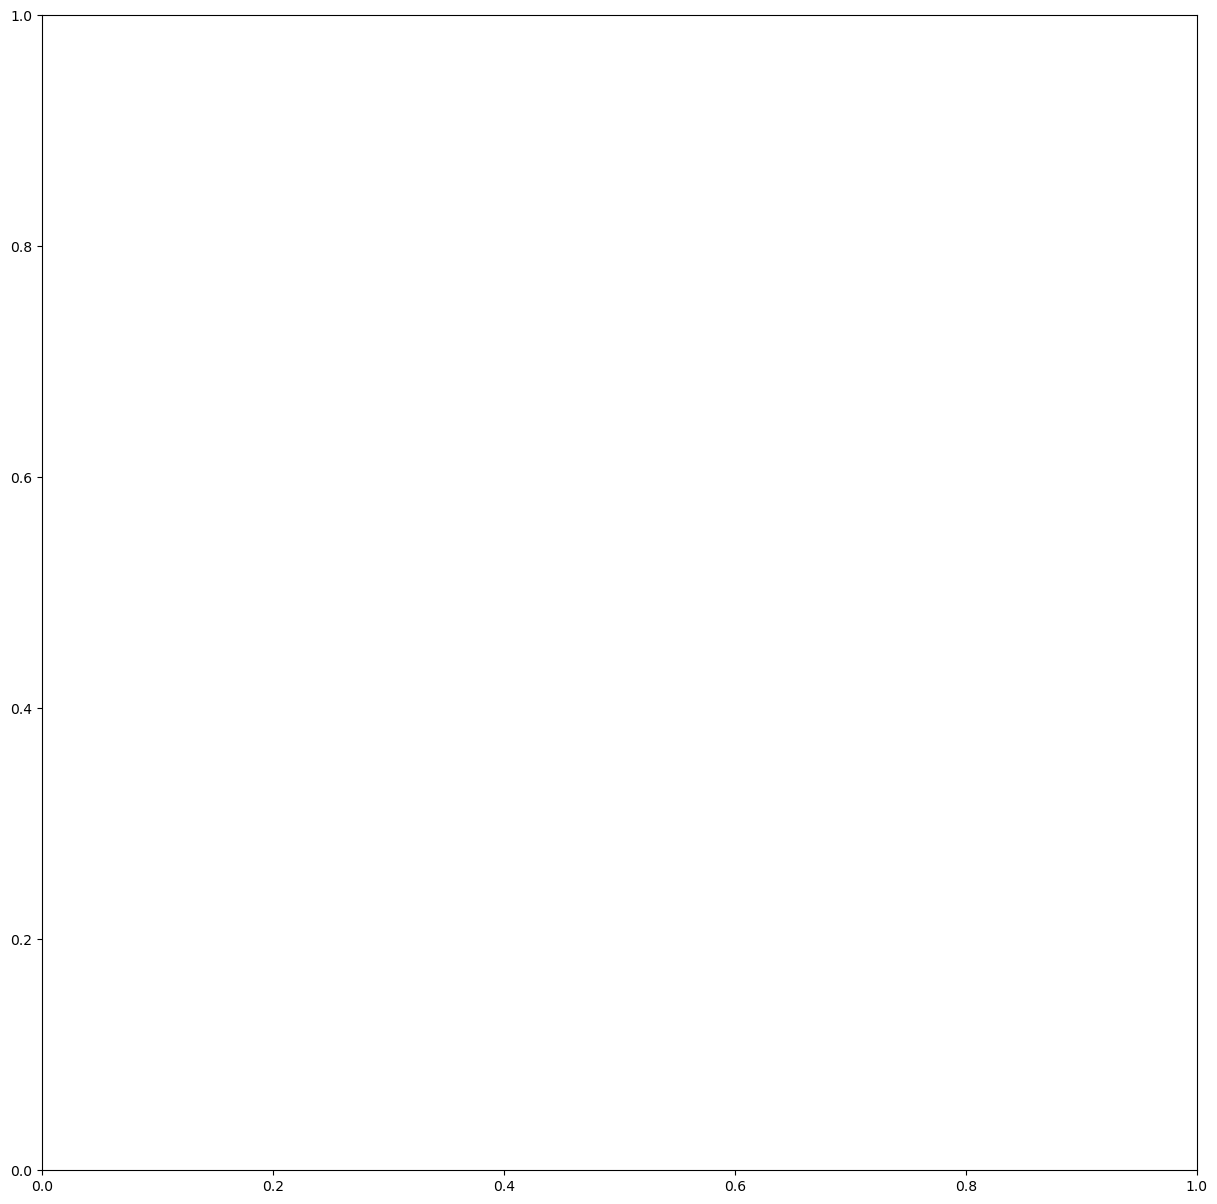

/nix/store/1szch77azxlyl3bd4r26fnxd1gsga2px-python3-3.13.8-env/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


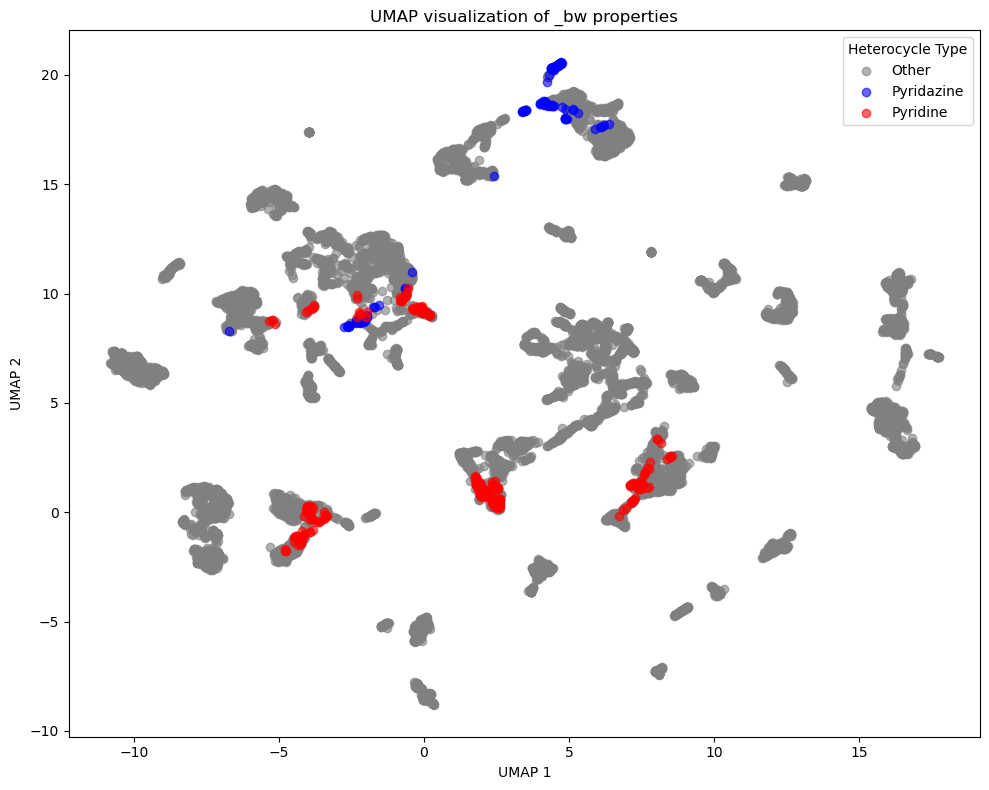

In [15]:
# UMAP plot of data clustering only on "_bw" properties
from sklearn.preprocessing import StandardScaler
import umap.umap_ as umap
import matplotlib.pyplot as plt

data_bw = df.fillna(0).values  # Fill NaNs

# Standardize the data
scaler = StandardScaler()
data_scaled = scaler.fit_transform(data_bw)

# Apply UMAP
umap_model = umap.UMAP(random_state=42)
umap_results = umap_model.fit_transform(data_scaled)

# Extract heterocycle types from index
heterocycle_types = df.index.str.split('_').str[0]

# Create masks for each type
pyridazine_mask = heterocycle_types == 'pyridazine'
pyridine_mask = heterocycle_types == 'pyridine'
others_mask = ~(pyridazine_mask | pyridine_mask)

# Plot
plt.figure(figsize=(10, 8))

# Plot others in grey first (below)
plt.scatter(umap_results[others_mask, 0], umap_results[others_mask, 1], c='grey', alpha=0.6, label='Other')

# Plot pyridazine in blue
plt.scatter(umap_results[pyridazine_mask, 0], umap_results[pyridazine_mask, 1], c='blue', alpha=0.6, label='Pyridazine')

# Plot pyridine in red on top
plt.scatter(umap_results[pyridine_mask, 0], umap_results[pyridine_mask, 1], c='red', alpha=0.6, label='Pyridine')

# Add legend
plt.legend(title="Heterocycle Type")

plt.title('UMAP visualization of _bw properties')
plt.xlabel('UMAP 1')
plt.ylabel('UMAP 2')
plt.tight_layout()
plt.show()

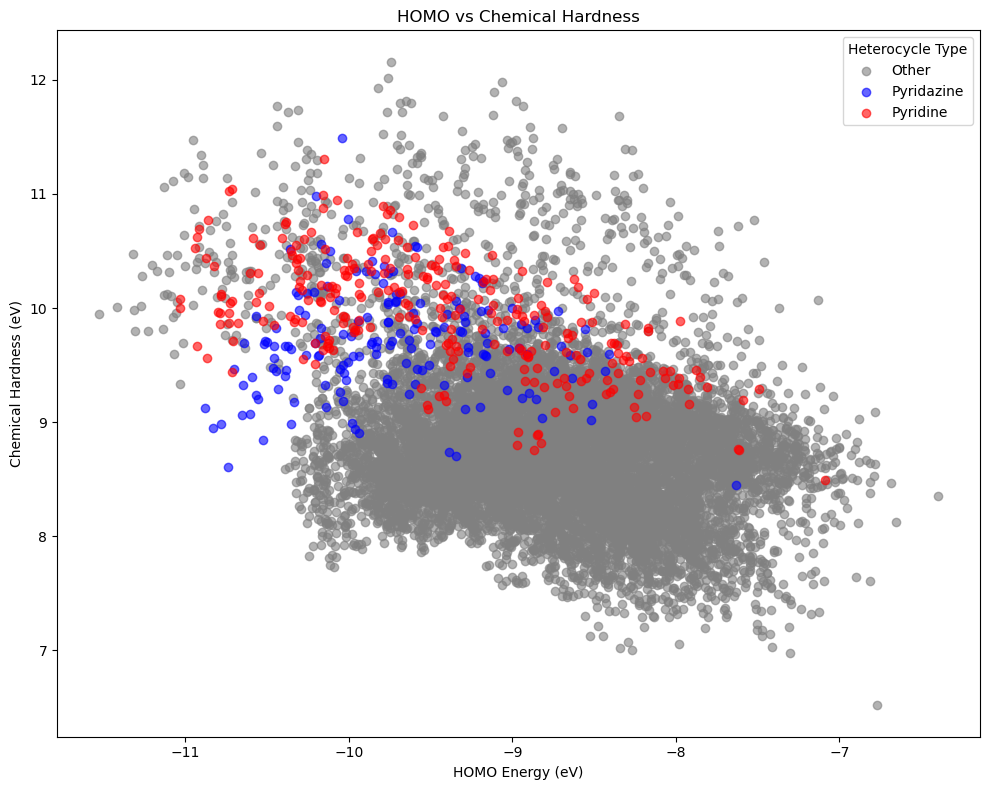

In [59]:
plt.figure(figsize=(10, 8))

# Extract heterocycle types from index
heterocycle_types = df.index.str.split('_').str[0]

# Create masks for each type
pyridazine_mask = (heterocycle_types == 'pyridazine')# | (heterocycle_types == 'cinnoline') | (heterocycle_types == 'phthalazine')
pyridine_mask = heterocycle_types == 'pyridine'
others_mask = ~(pyridazine_mask | pyridine_mask)

# Plot others in grey first (below)
plt.scatter(df.loc[others_mask, "HOMO_energy"], df.loc[others_mask, "chemical_hardness"], c='grey', alpha=0.6, label='Other')

# Plot pyridazine in blue
plt.scatter(df.loc[pyridazine_mask, "HOMO_energy"], df.loc[pyridazine_mask, "chemical_hardness"], c='blue', alpha=0.6, label='Pyridazine')

# Plot pyridine in red on top
plt.scatter(df.loc[pyridine_mask, "HOMO_energy"], df.loc[pyridine_mask, "chemical_hardness"], c='red', alpha=0.6, label='Pyridine')

# Add legend
plt.legend(title="Heterocycle Type")

plt.xlabel("HOMO Energy (eV)")
plt.ylabel("Chemical Hardness (eV)")
plt.title("HOMO vs Chemical Hardness")
plt.tight_layout()
plt.show()

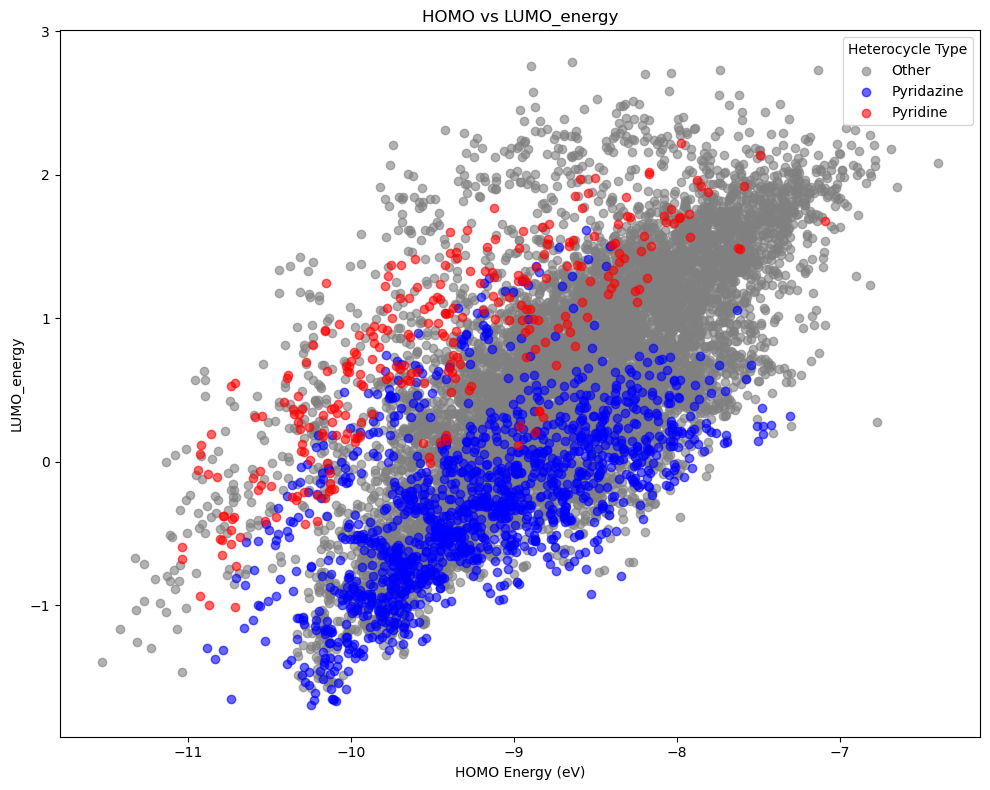

In [58]:
plt.figure(figsize=(10, 8))

# Extract heterocycle types from index
heterocycle_types = df.index.str.split('_').str[0]

# Create masks for each type
pyridazine_mask = (heterocycle_types == 'pyridazine') | (heterocycle_types == 'cinnoline') | (heterocycle_types == 'phthalazine')
pyridine_mask = (heterocycle_types == 'pyridine')
others_mask = ~(pyridazine_mask | pyridine_mask)

# Plot others in grey first (below)
plt.scatter(df.loc[others_mask, "HOMO_energy"], df.loc[others_mask, "LUMO_energy"], c='grey', alpha=0.6, label='Other')

# Plot pyridazine in blue
plt.scatter(df.loc[pyridazine_mask, "HOMO_energy"], df.loc[pyridazine_mask, "LUMO_energy"], c='blue', alpha=0.6, label='Pyridazine')

# Plot pyridine in red on top
plt.scatter(df.loc[pyridine_mask, "HOMO_energy"], df.loc[pyridine_mask, "LUMO_energy"], c='red', alpha=0.6, label='Pyridine')

# Add legend
plt.legend(title="Heterocycle Type")

plt.xlabel("HOMO Energy (eV)")
plt.ylabel("LUMO_energy")
plt.title("HOMO vs LUMO_energy")
plt.tight_layout()
plt.show()

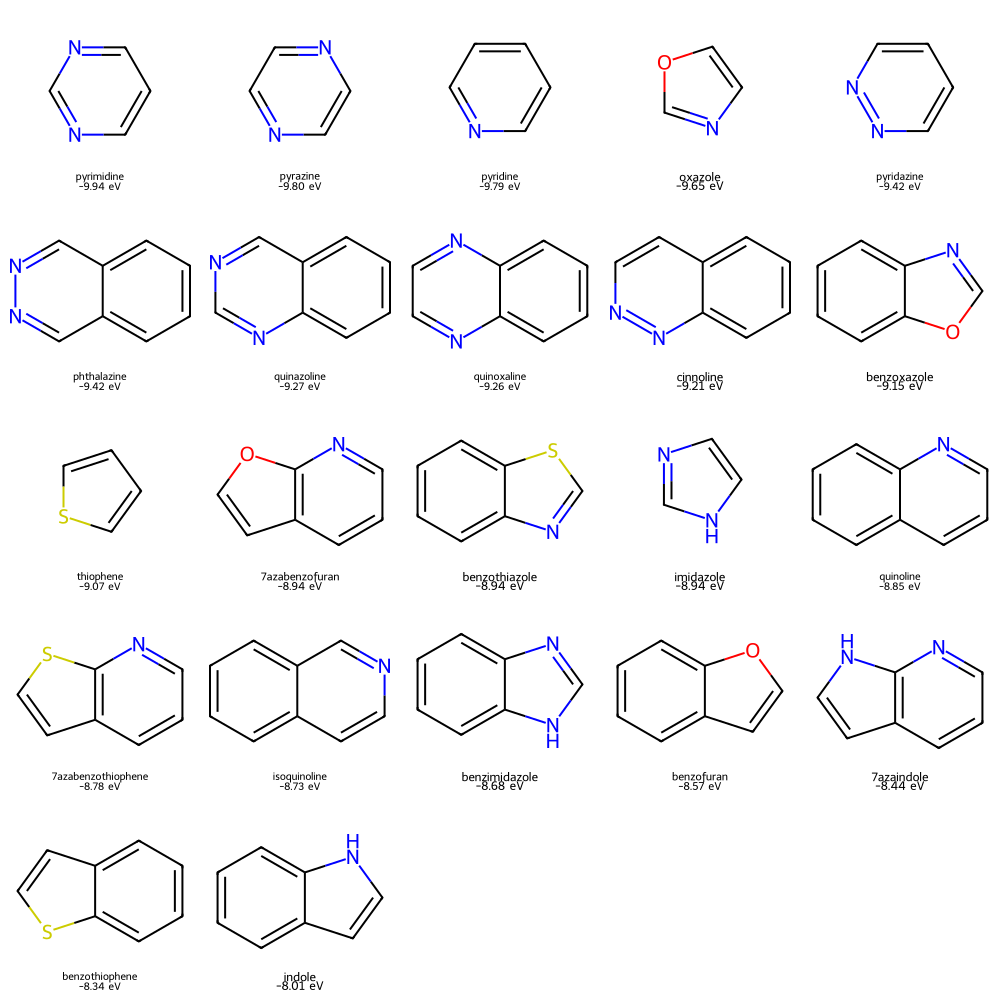

In [52]:
from rdkit.Chem import Draw

# Sort df by HOMO_energy
df_sorted = base_library.sort_values('HOMO_energy')

# Get molecules and legends
mols = df_sorted['mol'].tolist()
legends = [f"{idx}\n{homo:.2f} eV" for idx, homo in zip(df_sorted.index, df_sorted['HOMO_energy'])]

# Create grid image
img = Draw.MolsToGridImage(mols, legends=legends, molsPerRow=5, subImgSize=(200,200), maxMols=len(mols), returnPNG=False)

# Display the grid
display(img)

# save image
img.save("base_library_homo_energy_grid.png")



In [53]:
from rdkit.Chem import Draw

# Sort df by HOMO_energy
df_sorted = pyridine_library.sort_values('HOMO_energy')

# Get molecules and legends
mols = df_sorted['mol'].tolist()
legends = [f"{idx}\n{homo:.2f} eV" for idx, homo in zip(df_sorted.index, df_sorted['HOMO_energy'])]

# Create grid image
img = Draw.MolsToGridImage(mols, legends=legends, molsPerRow=5, subImgSize=(200,200), maxMols=len(mols), returnPNG=False)

# Display the grid
display(img)

# save image
img.save("pyridine_library_homo_energy_grid.png")

In [ ]:
base_library